<h1>Step 1: Understand the problem statement</h1>

<h3>The Wine dataset</h3>

https://archive.ics.uci.edu/dataset/109/wine

These data are the results of a chemical analysis of wines grown in the same region
in Italy, derived from three different cultivars (grape varieties). The analysis
determined the quantities of 13 constituents found in each of the three types of wine:

1. Alcohol
2. Malic acid
3. Ash
4. Alcalinity of ash
5. Magnesium
6. Total phenols
7. Flavanoids
8. Nonflavanoid phenols
9. Proanthocyanins
10. Colour intensity
11. Hue
12. OD280/OD315 of diluted wines
13. Proline

The 13 attributes are numerical chemical measurements. The final column,
**Customer_Segment**, records which of the three wine types each row really is
(1, 2 or 3) — 178 wines in total.

**The game for this lab:** we hide Customer_Segment from the clustering algorithm,
let K-Means group the wines purely by their chemistry, then compare the discovered groups with the supplied classes. Labels also guide
the ANOVA-based visualisation, but never the PCA or K-means fit.

### Dataset label clarification

The university-provided `Wine.csv` names its final column `Customer_Segment`. A row-by-row check against scikit-learn’s bundled Wine dataset confirms that the 13 measurements match and this column equals its target plus one. The measurements and class assignments match scikit-learn’s Wine dataset. The university CSV numbers the classes **1–3**, whereas scikit-learn numbers them **0–2**. It therefore represents the **wine cultivar class (1–3)** in the original [UCI Wine dataset](https://archive.ics.uci.edu/dataset/109/wine), rather than a customer segment. The UCI page does not name the three cultivars.

This column is **excluded from scaling, PCA, and clustering** and used to evaluate class agreement and to choose the ANOVA visualisation axes. Cluster IDs are arbitrary, so they are mapped to class labels before displaying the confusion matrix.

<h1> Step 2: Import the libraries and dataset </h1>

In [1]:
# cap the maths library to one thread — avoids the Windows/MKL
# memory-leak warning in K-Means (must run before sklearn is imported)
import os
import sys

if sys.platform == "win32":
    os.environ["OMP_NUM_THREADS"] = "1"
    print("Windows OS detected. Limiting maths library to one thread to avoid memory leak warning in K-Means.")

# pandas          -> loading and handling the data
# matplotlib      -> plotting (including the 3D plot later)
# StandardScaler  -> put all 13 measurements on the same scale
# KMeans          -> the clustering algorithm
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Additional evaluation, assignment matching, and plotting utilities not used in the original lab
from sklearn.metrics import adjusted_rand_score, ConfusionMatrixDisplay
from sklearn.feature_selection import f_classif
from IPython.display import Markdown, display
from scipy.optimize import linear_sum_assignment
import numpy as np
import seaborn as sns
import numpy.typing as npt
from matplotlib.axes import Axes

from notebook_display import display_table


# Read the dataset
data = pd.read_csv("data/Wine.csv")

# Look at the first few rows
data.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


<h2>Exploratory Data Analysis (EDA)</h2>

<h3>Dataset integrity</h3>

In [2]:
null_counts = data.isna().sum()

if null_counts.any():
    print("Nulls per column:")
    print(null_counts)
else:
    print("No missing values found.")

No missing values found.


In [3]:
print("Shape:", data.shape)
print("Missing values:", data.isna().sum().sum())
print("Duplicates:", data.duplicated().sum())

data.info()

Shape: (178, 14)
Missing values: 0
Duplicates: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
 13  Customer_Segment      178 non-null    int64  
dtypes: float64(11), int64(3)


In [4]:
display(Markdown(
    f"Examples of minimum and maximum values:\n\n"
    f"- Proline: {data['Proline'].min()} to {data['Proline'].max()}\n"
    f"- Hue: {data['Hue'].min()} to {data['Hue'].max()}"
))

Examples of minimum and maximum values:

- Proline: 278 to 1680
- Hue: 0.48 to 1.71

### Why scaling is important

The wine dataset contains chemical measurements with different units and numerical ranges. For example, `Proline` has much larger values than `Hue`.

**K-means uses distances** to assign clusters, while **PCA identifies directions of greatest variance**. Without scaling, features with larger numerical ranges can dominate both methods, regardless of their usefulness.

We therefore standardise the features to **mean 0 and standard deviation 1** before applying PCA and K-means. The `Customer_Segment` column is excluded because it is a class label, not an input feature.

In [5]:
'''
# X = the 13 chemical measurements ONLY — we drop Customer_Segment so the
# clustering never sees the answer it is supposed to discover
X = data.drop('Customer_Segment', axis=1)
'''
# Select the original measurements explicitly so rerunning this cell cannot
# include cluster columns added later in the notebook.
feature_columns = [
    "Alcohol", "Malic_Acid", "Ash", "Ash_Alcanity", "Magnesium",
    "Total_Phenols", "Flavanoids", "Nonflavanoid_Phenols",
    "Proanthocyanins", "Color_Intensity", "Hue", "OD280", "Proline",
]
X = data.loc[:, feature_columns].copy()
true_labels = data["Customer_Segment"]

# Standardisation prevents large-range measurements dominating distances.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

<h3>Descriptive statistics</h3>

In [6]:
X.describe().T

,count,mean,std,min,25%,50%,75%,max
Alcohol,178.0,13.000618,0.811827,11.03,12.3625,13.050,13.6775,14.83
Malic_Acid,178.0,2.336348,1.117146,0.74,1.6025,1.865,3.0825,5.80
Ash,178.0,2.366517,0.274344,1.36,2.2100,2.360,2.5575,3.23
Ash_Alcanity,178.0,19.494944,3.339564,10.60,17.2000,19.500,21.5000,30.00
Magnesium,178.0,99.741573,14.282484,70.00,88.0000,98.000,107.0000,162.00
Total_Phenols,178.0,2.295112,0.625851,0.98,1.7425,2.355,2.8000,3.88
Flavanoids,178.0,2.029270,0.998859,0.34,1.2050,2.135,2.8750,5.08
Nonflavanoid_Phenols,178.0,0.361854,0.124453,0.13,0.2700,0.340,0.4375,0.66
Proanthocyanins,178.0,1.590899,0.572359,0.41,1.2500,1.555,1.9500,3.58
Color_Intensity,178.0,5.058090,2.318286,1.28,3.2200,4.690,6.2000,13.00


<h3>Feature distributions</h3>

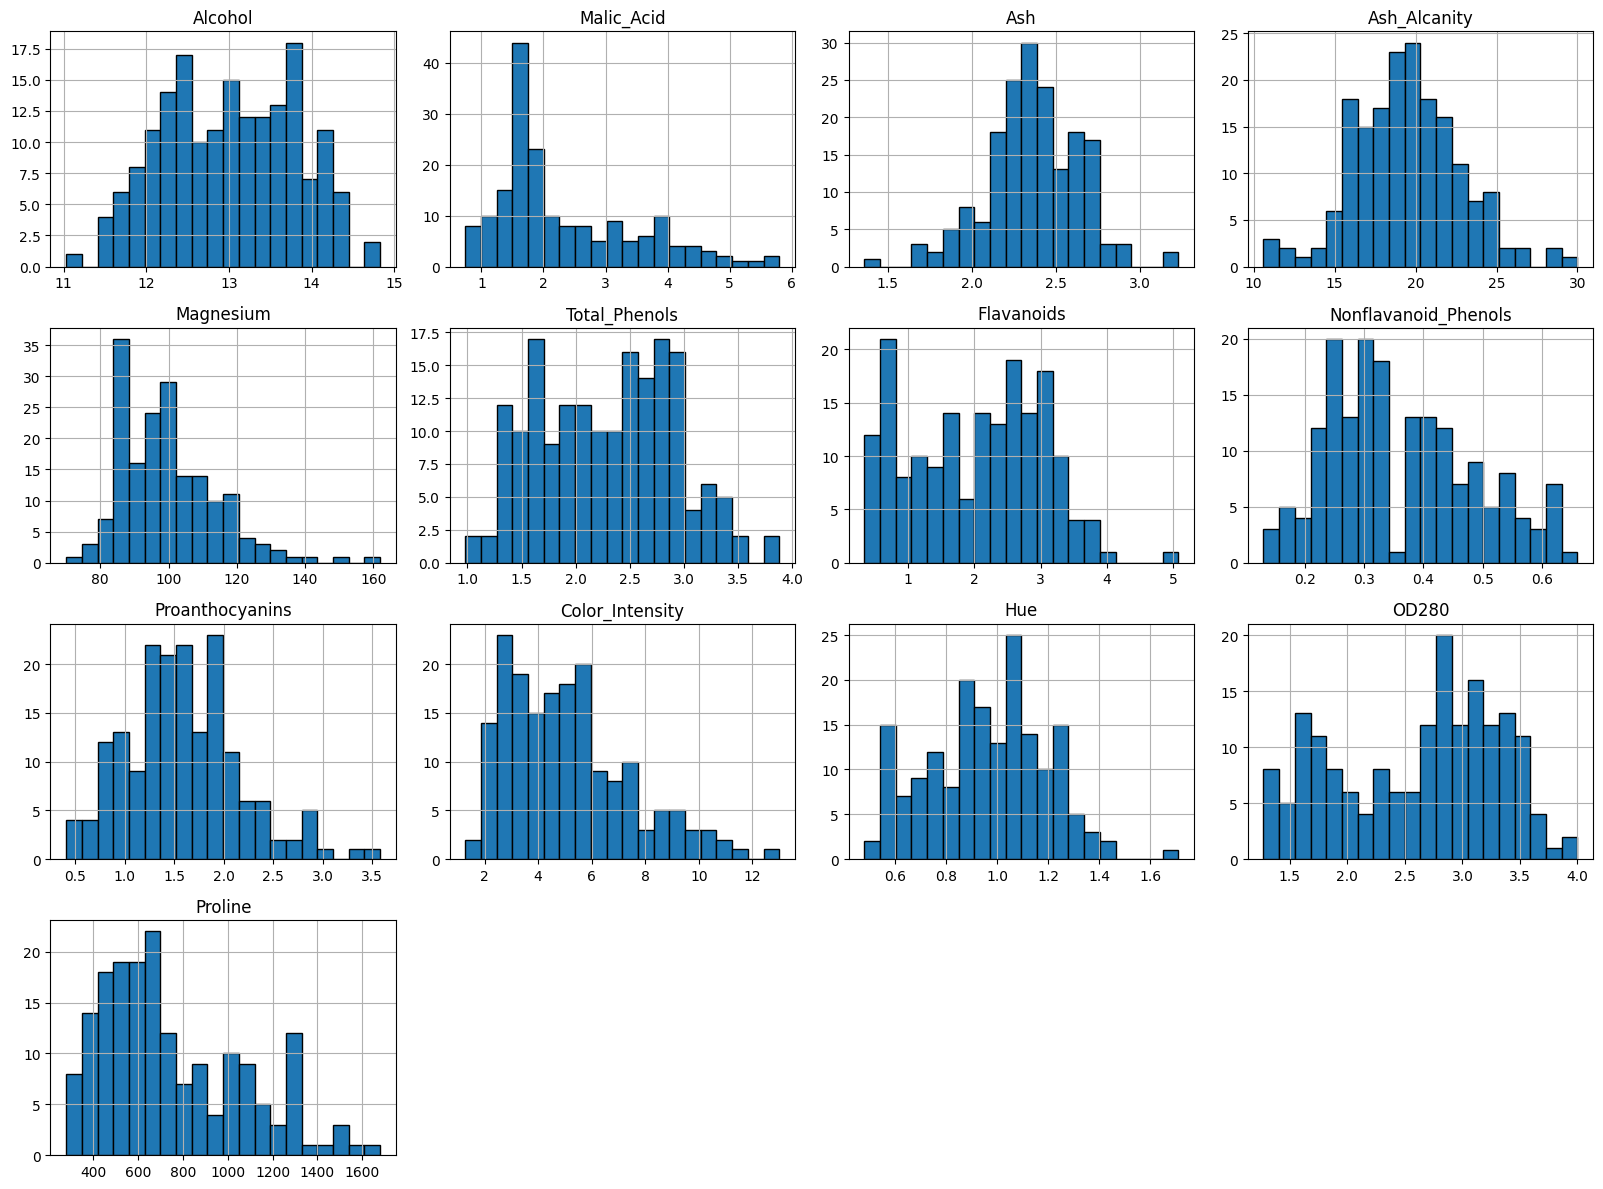

In [7]:
X.hist(
    figsize=(16, 12),
    bins=20,
    edgecolor="black"
)

plt.tight_layout()
plt.show()

<h3>Correlation analysis</h3>

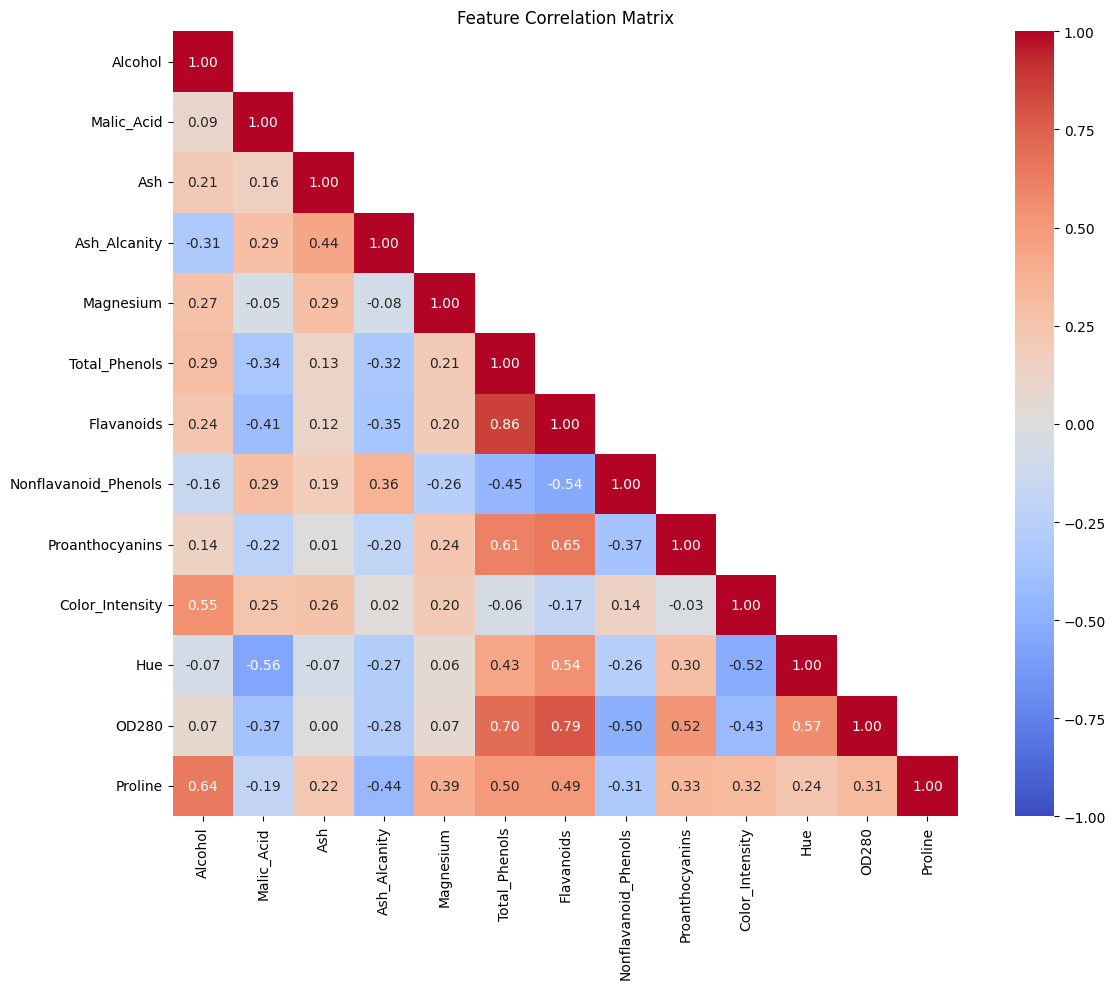

In [8]:
show_complete_matrix_bool = False # As the matrix is the same across the diagonal there's no need to show the complete matrix

plt.figure(figsize=(13, 10))

if show_complete_matrix_bool:
    sns.heatmap(
        X.corr(),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        square=True
    )

    plt.title("Feature Correlation Matrix")
else:
    corr = X.corr()

    # Mask the upper triangle, excluding the diagonal
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

    sns.heatmap(
        corr,
        mask=mask,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        square=True
    )

    plt.title("Feature Correlation Matrix")
    plt.tight_layout()

plt.show()

In [9]:
THRESHOLD = 0.5

corr = X.corr()

# Extract unique correlations, excluding the diagonal
mask = np.tril(np.ones_like(corr, dtype=bool), k=-1)
correlations = corr.where(mask).stack()

# Filter and sort by absolute correlation
strong_corr = correlations[
    correlations.abs() >= THRESHOLD
].sort_values(key=abs, ascending=False)

print(strong_corr)

Flavanoids            Total_Phenols           0.864564
OD280                 Flavanoids              0.787194
                      Total_Phenols           0.699949
Proanthocyanins       Flavanoids              0.652692
Proline               Alcohol                 0.643720
Proanthocyanins       Total_Phenols           0.612413
OD280                 Hue                     0.565468
Hue                   Malic_Acid             -0.561296
Color_Intensity       Alcohol                 0.546364
Hue                   Flavanoids              0.543479
Nonflavanoid_Phenols  Flavanoids             -0.537900
Hue                   Color_Intensity        -0.521813
OD280                 Proanthocyanins         0.519067
                      Nonflavanoid_Phenols   -0.503270
dtype: float64


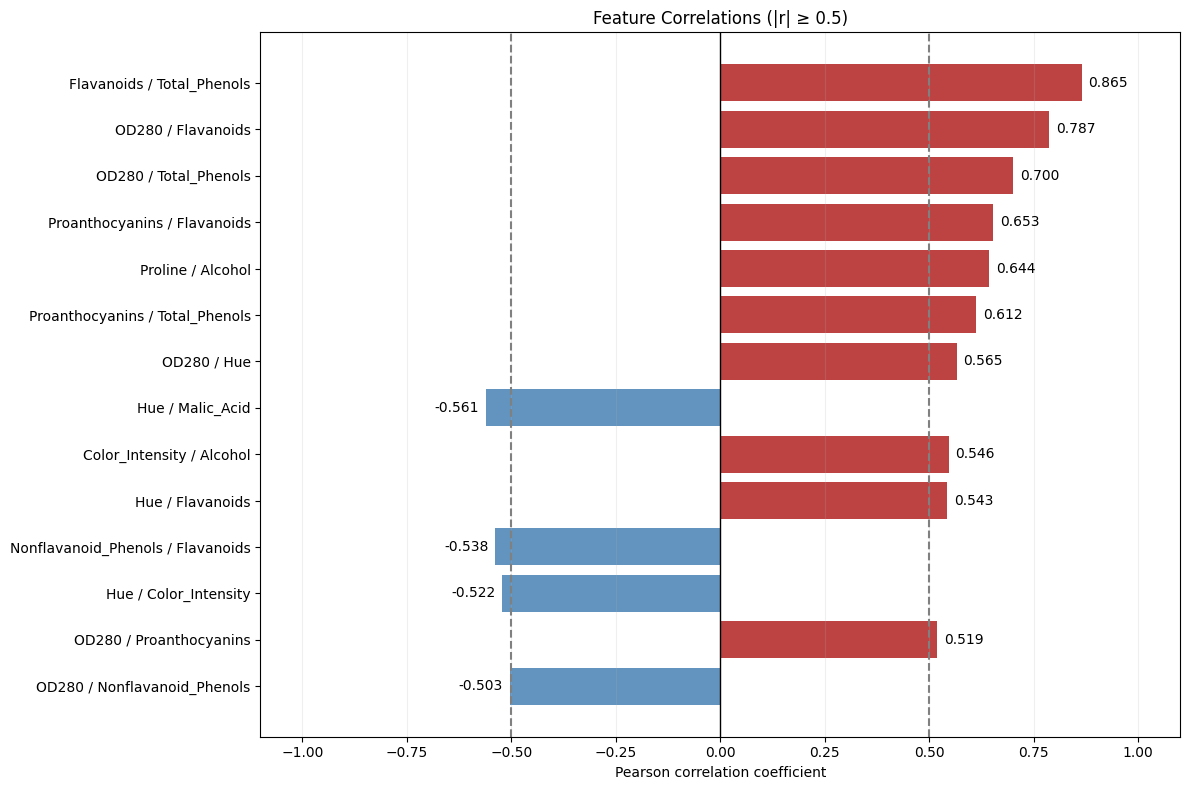

In [10]:
# Create labels for each feature pair
feature_pair_labels = [f"{a} / {b}" for a, b in strong_corr.index]
values = strong_corr.values

# Assign colours according to the correlation sign
colours = ["firebrick" if r > 0 else "steelblue" for r in values]

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(feature_pair_labels, values, color=colours, alpha=0.85)

# Display correlation values
ax.bar_label(bars, fmt="%.3f", padding=5)

# Reference lines
ax.axvline(0, color="black", linewidth=1)
ax.axvline(THRESHOLD, color="grey", linestyle="--")
ax.axvline(-THRESHOLD, color="grey", linestyle="--")

# Formatting
ax.set_xlim(-1.1, 1.1)
ax.invert_yaxis()
ax.set_xlabel("Pearson correlation coefficient")
ax.set_title(f"Feature Correlations (|r| ≥ {THRESHOLD})")
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()

### Selecting three features for visualisation

We use **ANOVA F-scores** (`f_classif`) to rank the chemical measurements by how strongly they distinguish the classes in `Customer_Segment`.

Each feature is evaluated individually by comparing variation **between class means** with variation **within classes**. A higher F-score indicates stronger class separation.

The table lists features from highest to lowest score. We will use the **three highest-ranked features** as the axes of a 3-D scatter plot.

This selection uses the known class labels to guide visualisation; it does not determine the clusters or change PCA. These are the strongest features individually according to this measure, but not necessarily the best three-feature combination.

**Note:** `X` must contain only the original chemical measurements, excluding `Customer_Segment` and any added `clusters` column.

In [11]:
# X contains only the original measurements.
scores, _ = f_classif(X, true_labels)

feature_ranking = (
    pd.DataFrame({"Feature": X.columns, "F-score": scores})
    .sort_values("F-score", ascending=False)
    .reset_index(drop=True)
)

display_table(feature_ranking, formats={"F-score": "{:.2f}"})

Feature,F-score
Flavanoids,233.93
Proline,207.92
OD280,189.97
Alcohol,135.08
Color_Intensity,120.66
Hue,101.32
Total_Phenols,93.73
Malic_Acid,36.94
Ash_Alcanity,35.77
Proanthocyanins,30.27


<h1>Step 3: Explore the number of clusters using the elbow method</h1>

Fit K-means for k = 1 to 10 on all 13 standardised features and record inertia
(the within-cluster sum of squared distances to the centres). Look for a bend
after which additional clusters produce smaller reductions.

This is a heuristic, not proof of an optimal cluster count. The later PCA
experiments hold this cluster count fixed to isolate the effects of preprocessing;
the elbow here is measured in the 13-feature space, not the PCA spaces.

[KMeans API Reference](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)

The original lab specified `init='k-means++'` in some K-means models and
omitted it in others. Since `'k-means++'` is already the default, both forms
use the same initialisation method. We specify it explicitly in every model
to make the configuration consistent and easier to compare across experiments.

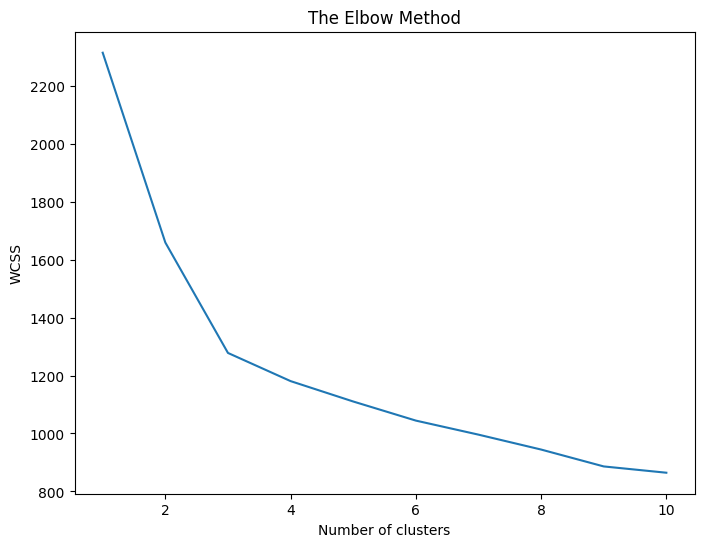

In [12]:
# Basically, number of clusters = the x-axis value of the point that is the
# corner of the "elbow" (the plot often looks like an elbow)
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=12, random_state=0)
    kmeans.fit(X_scaled)                # cluster the SCALED measurements
    wcss.append(kmeans.inertia_)        # inertia = total spread within clusters

f3, ax = plt.subplots(figsize=(8, 6))
plt.plot(range(1, 11), wcss)
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()

<h1>Step 4: Apply K-means clustering to all 13 scaled features</h1>

The inertia curve suggests an elbow around **k = 3**. In this run, inertia falls
from about 2314 to 1659 to 1278 for k = 1, 2, 3, then to about 1181 at k = 4.
The reduction from k = 3 to 4 is about 97, compared with 381 from k = 2 to 3.
The later reductions are smaller, but not zero.

We use KneeLocator to estimate the bend and inspect it against the plot.
Three clusters are a reasonable working choice, consistent with the three
provided classes. This does not prove that the groups recover those classes.

This preliminary model uses all 13 scaled features. The two-component PCA
baseline is a separate model fitted in Step 6.

In [13]:
use_a_predefined_number_of_clusters_bool = False # The original code uses 3 as a predefined value.

if use_a_predefined_number_of_clusters_bool:
    print("Using predefined number of clusters.")
    clusterNum = 3
else:
    print("Using elbow method to determine the number of clusters.")
    # Estimate the elbow; the result depends on the inertia curve. It will end up selecting 3.
    from kneed import KneeLocator

    # Use the same k values you used when building inertia
    k_values = range(1, len(wcss) + 1)

    elbow = KneeLocator(
        list(k_values),
        wcss,
        curve='convex',
        direction='decreasing',
    )

    clusterNum = elbow.knee

    if clusterNum is None:
        raise ValueError("No clear elbow found; inspect the inertia plot.")

print(f"Selected number of clusters: {clusterNum}")

# Fit the preliminary model on all 13 scaled features.
#clusterNum = 3
k_means = KMeans(init='k-means++', n_clusters=clusterNum, n_init=12, random_state=0)
k_means.fit(X_scaled)

# labels_ holds the cluster number assigned to each of the 178 wines
labels = k_means.labels_
print(labels)

Using elbow method to determine the number of clusters.
Selected number of clusters: 3
[2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2
 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 1 0 0 2 0 0 0 0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1]


<h1>Step 5: Add the label</h1>
We attach each wine's cluster number to the dataset, then average the 13
measurements within each cluster — the "chemical fingerprint" of each group.

In [14]:
display(Markdown("Displaying the first rows in `data` (data has been transposed for better readability)"))
# We assign the labels to each row in the dataframe.
data['Clus_km'] = labels
display(data.head().T)

display(Markdown("\nDisplaying each cluster averages (data has been transposed for better readability)"))
# the average of each measurement within each cluster —
# the "chemical fingerprint" of each group of wines
display(data.groupby('Clus_km')[X.columns].mean().T)

Displaying the first rows in `data` (data has been transposed for better readability)

,0,1,2,3,4
Alcohol,14.23,13.20,13.16,14.37,13.24
Malic_Acid,1.71,1.78,2.36,1.95,2.59
Ash,2.43,2.14,2.67,2.50,2.87
Ash_Alcanity,15.60,11.20,18.60,16.80,21.00
Magnesium,127.00,100.00,101.00,113.00,118.00
Total_Phenols,2.80,2.65,2.80,3.85,2.80
Flavanoids,3.06,2.76,3.24,3.49,2.69
Nonflavanoid_Phenols,0.28,0.26,0.30,0.24,0.39
Proanthocyanins,2.29,1.28,2.81,2.18,1.82
Color_Intensity,5.64,4.38,5.68,7.80,4.32



Displaying each cluster averages (data has been transposed for better readability)

Clus_km,0,1,2
Alcohol,12.250923,13.134118,13.676774
Malic_Acid,1.897385,3.307255,1.997903
Ash,2.231231,2.417647,2.466290
Ash_Alcanity,20.063077,21.241176,17.462903
Magnesium,92.738462,98.666667,107.967742
Total_Phenols,2.247692,1.683922,2.847581
Flavanoids,2.050000,0.818824,3.003226
Nonflavanoid_Phenols,0.357692,0.451961,0.292097
Proanthocyanins,1.624154,1.145882,1.922097
Color_Intensity,2.973077,7.234706,5.453548


<h1>Step 5.1: View the preliminary clusters in 3D</h1>

Each wine has 13 measurements. The first plots show three manually chosen
features; the next uses the three highest ANOVA F-scores. Both are partial views
of the 13-feature clustering. The ANOVA ranking uses the supplied class labels
only to choose visualisation axes.

PCA next provides another partial view: combinations of measurements that
maximise retained variance for a given number of components. Two components
cannot preserve all the original information.

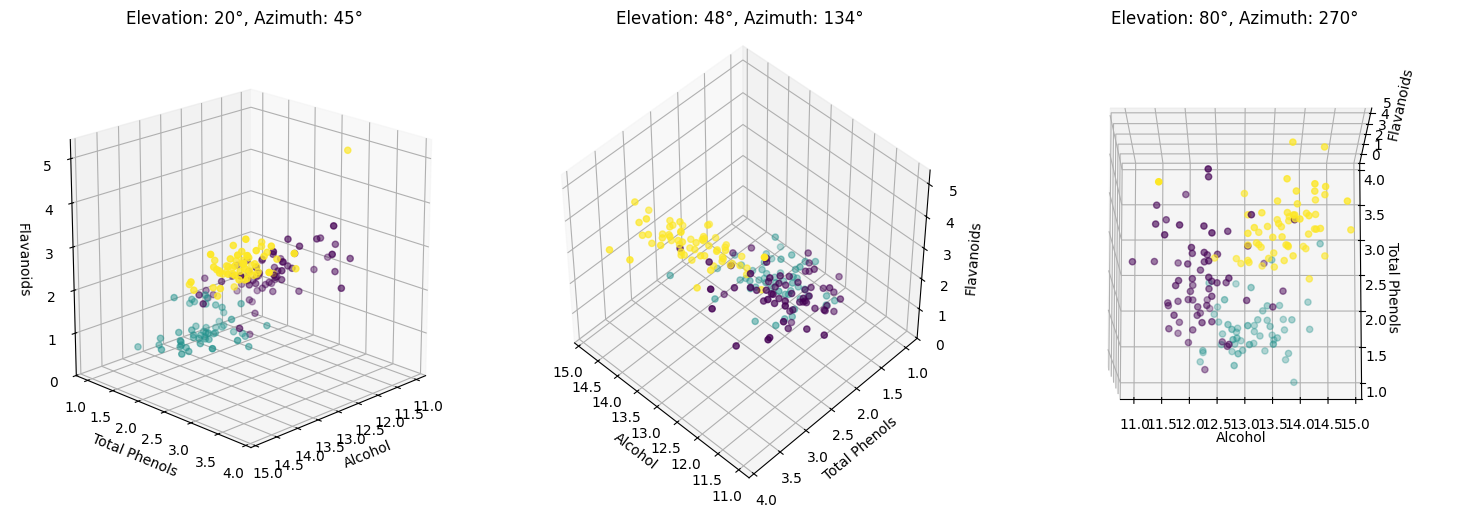

In [15]:
show_one_image_bool = False # set to true to revert to the lab original

if show_one_image_bool:
    # create a 3-dimensional graph of three chosen measurements, coloured by cluster
    f4 = plt.figure(1, figsize=(8, 6))
    ax = f4.add_subplot(projection='3d')    # current matplotlib way to make 3D axes
    ax.view_init(elev=48, azim=134)         # same viewing angle as the original

    ax.set_xlabel('alcohol')
    ax.set_ylabel('total Phenols')
    ax.set_zlabel('Flavanoids')

    ax.scatter(X.iloc[:, 0], X.iloc[:, 5], X.iloc[:, 6], c=labels)
    ax.set_box_aspect((1, 1, 1), zoom=0.9) # Otherwise the Z axis gets clipped
    plt.show()
else:
    fig = plt.figure(figsize=(15, 5))

    for i, (elev, azim) in enumerate([(20, 45), (48, 134), (80, 270)], start=1):
        ax = fig.add_subplot(1, 3, i, projection="3d")
        ax.scatter(X.iloc[:, 0], X.iloc[:, 5], X.iloc[:, 6], c=labels)

        ax.view_init(elev=elev, azim=azim)
        ax.set_xlabel("Alcohol")
        ax.set_ylabel("Total Phenols")
        ax.set_zlabel("Flavanoids")
        ax.set_title(f"Elevation: {elev}°, Azimuth: {azim}°")
        ax.set_box_aspect((1, 1, 1), zoom=0.9) # Otherwise the Z axis gets clipped

    plt.tight_layout()
    plt.show()

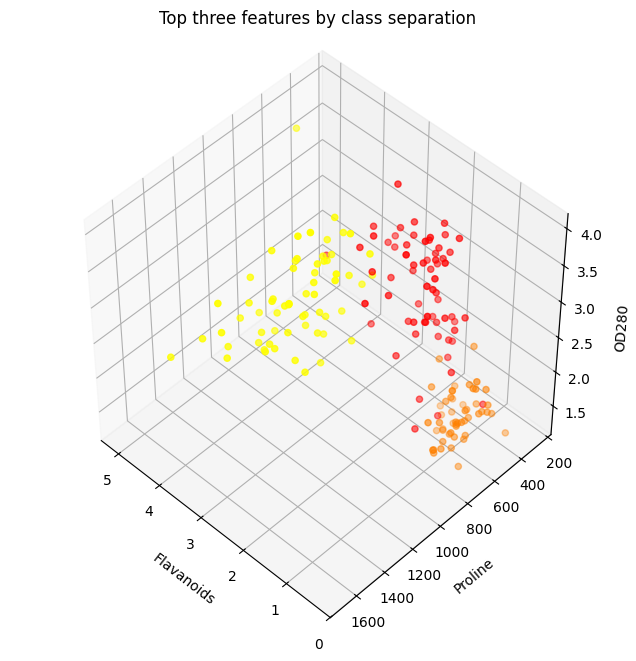

In [16]:
top_three = feature_ranking["Feature"].head(3).tolist()

fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(projection="3d")

ax.scatter(
    X[top_three[0]],
    X[top_three[1]],
    X[top_three[2]],
    c=labels,
    cmap="autumn"
)

# Replace underscores so labels are easier to read
ax.set_xlabel(top_three[0].replace("_", " "), labelpad=10)
ax.set_ylabel(top_three[1].replace("_", " "), labelpad=10)
ax.set_zlabel(top_three[2].replace("_", " "), labelpad=10)

ax.set_title("Top three features by class separation")
ax.view_init(elev=48, azim=134)

ax.set_box_aspect((1, 1, 1), zoom=0.9)
#fig.subplots_adjust(left=0.15, right=0.85, bottom=0.15, top=0.90)
plt.show()

<h1>Step 6: Reduce the 13 dimensions to 2 with PCA</h1>
Principal Component Analysis finds the directions along which the wines vary the
most, and re-expresses each wine using just those directions. We keep the top 2 —
turning every wine's 13 numbers into 2, chosen to preserve as much of the
variation as possible.

In [17]:
number_of_principal_components_to_keep = 2
# create a PCA that keeps 2 components and fit it on the scaled measurements
pca_wines = PCA(number_of_principal_components_to_keep)
pca_wines.fit(X_scaled)

PCA(n_components=2)

In [18]:
def display_pca_explained_variance(variance_ratios: npt.ArrayLike) -> None:
    """Display each retained component’s variance ratio and their total."""
    variance_ratios = np.asarray(variance_ratios).ravel()

    variance_table = pd.DataFrame(
        {"Explained variance ratio": variance_ratios},
        index=[f"Component {i}" for i in range(1, len(variance_ratios) + 1)]
    )
    variance_table.index.name = "Component"
    variance_table.loc["Total"] = variance_ratios.sum()

    #display(variance_table.style.format("{:.4f}"))
    display_table(
        variance_table.reset_index(),
        formats={"Explained variance ratio": "{:.4f}"}
    )

    display(Markdown(
        f"We're keeping {len(variance_ratios)} principal components. "
        f"They retain "
        f"{variance_table.loc['Total', 'Explained variance ratio']:.2%} "
        f"of the total variance."
    ))

display_pca_explained_variance(pca_wines.explained_variance_ratio_)

Component,Explained variance ratio
Component 1,0.3620
Component 2,0.1921
Total,0.5541


We're keeping 2 principal components. They retain 55.41% of the total variance.

In [19]:
# convert every wine from 13 numbers down to 2
wines_p = pca_wines.transform(X_scaled)

Text(0, 0.5, 'Second principal component')

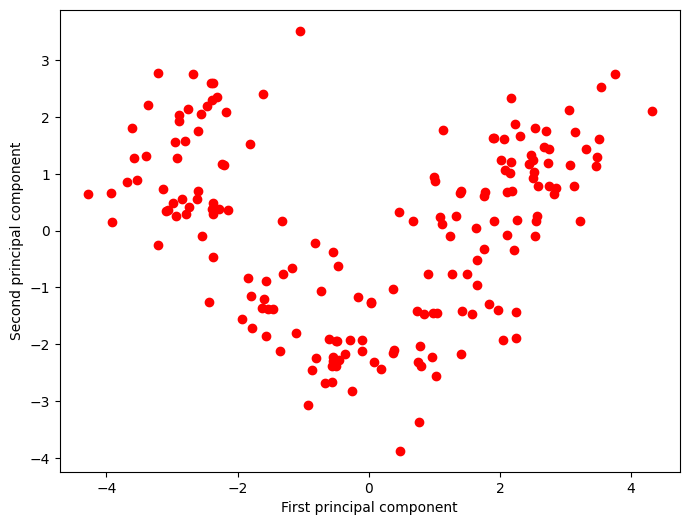

In [20]:
# plot all 178 wines on the new 2-D map (no clusters yet)
plt.figure(figsize=(8, 6))
plt.scatter(wines_p[:, 0], wines_p[:, 1], color='red')
plt.xlabel('First principal component')
plt.ylabel('Second principal component')

In [21]:
# the same 178 wines as a table — two columns instead of thirteen
wines_p2 = pd.DataFrame(wines_p)
wines_p2

,0,1
0,3.316751,1.443463
1,2.209465,-0.333393
2,2.516740,1.031151
3,3.757066,2.756372
4,1.008908,0.869831
...,...,...
173,-3.370524,2.216289
174,-2.601956,1.757229
175,-2.677839,2.760899
176,-2.387017,2.297347


In [22]:
# Hold the cluster count fixed across the PCA experiments.
# The elbow was estimated on all 13 scaled features.
km = KMeans(init="k-means++", n_clusters=clusterNum, n_init=12, random_state=0)
km

KMeans(n_clusters=3, n_init=12, random_state=0)

In [23]:
# cluster the wines using only their 2 principal components,
# and keep the coordinates of the 3 cluster centres
wines_predicted = km.fit_predict(wines_p)
centroids = km.cluster_centers_
centroids

array([[-0.16278513, -1.76758824],
       [ 2.26614991,  0.86559213],
       [-2.74392982,  1.2141906 ]])

In [24]:
# how many wines landed in each cluster
pd.Series(wines_predicted).value_counts()

0    65
1    64
2    49
Name: count, dtype: int64

In [25]:
display(Markdown("Showing the first 5 rows (wines) of the dataframe. Transposed for readability"))
# attach the new cluster number to the dataframe
data['clusters'] = wines_predicted
data.head().T

Showing the first 5 rows (wines) of the dataframe. Transposed for readability

,0,1,2,3,4
Alcohol,14.23,13.20,13.16,14.37,13.24
Malic_Acid,1.71,1.78,2.36,1.95,2.59
Ash,2.43,2.14,2.67,2.50,2.87
Ash_Alcanity,15.60,11.20,18.60,16.80,21.00
Magnesium,127.00,100.00,101.00,113.00,118.00
Total_Phenols,2.80,2.65,2.80,3.85,2.80
Flavanoids,3.06,2.76,3.24,3.49,2.69
Nonflavanoid_Phenols,0.28,0.26,0.30,0.24,0.39
Proanthocyanins,2.29,1.28,2.81,2.18,1.82
Color_Intensity,5.64,4.38,5.68,7.80,4.32


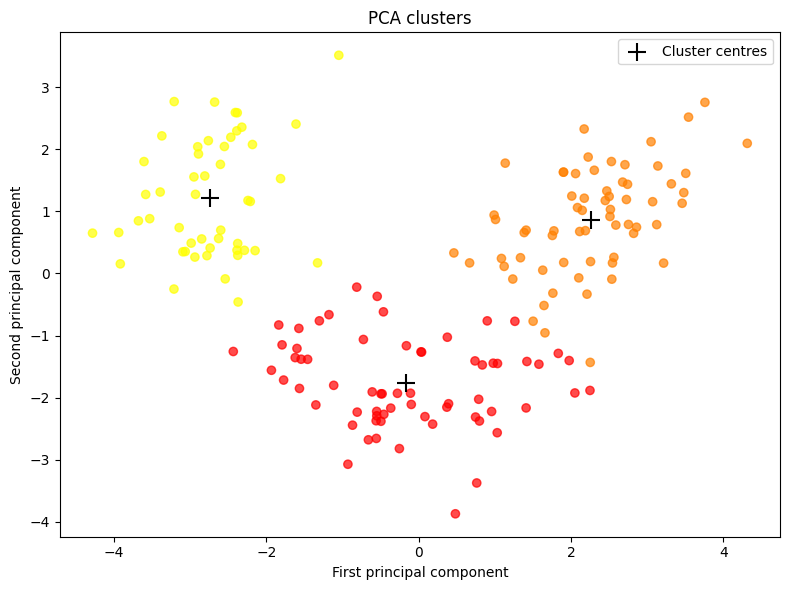

<Axes: title={'center': 'PCA clusters'}, xlabel='First principal component', ylabel='Second principal component'>

In [26]:
def plot_pca_clusters(
    coordinates: npt.ArrayLike,
    cluster_labels: npt.ArrayLike,
    centroids: npt.ArrayLike,
    *,
    ax: Axes | None = None,
    title: str = "PCA clusters",
) -> Axes:
    """Plot clusters and their centres on the first two PCA components.

    The finished picture: every wine on the 2-D map, coloured by cluster,
    with a black + marking each cluster centre
    """
    coordinates = np.asarray(coordinates)
    centroids = np.asarray(centroids)

    standalone = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))

    ax.scatter(
        coordinates[:, 0],
        coordinates[:, 1],
        c=np.asarray(cluster_labels).ravel(),
        cmap="autumn",
        alpha=0.7,
    )
    ax.scatter(
        centroids[:, 0],
        centroids[:, 1],
        color="black",
        marker="+",
        s=180,
        label="Cluster centres",
    )
    ax.set_xlabel("First principal component")
    ax.set_ylabel("Second principal component")
    ax.set_title(title)
    ax.legend()

    if standalone:
        plt.tight_layout()
        plt.show()

    return ax

plot_pca_clusters(wines_p, wines_predicted, centroids)

The **Adjusted Rand Index (ARI)** measures how closely the clusters match the known wine classes.

It considers pairs of wines and checks whether both groupings agree that they belong **together or apart**, then adjusts for agreement expected by chance.

| ARI value | Meaning |
|---|---|
| **1.0** | Perfect agreement |
| **Around 0** | Agreement similar to random assignments |
| **Below 0** | Less agreement than expected by chance |

An ARI close to 1 indicates strong agreement. ARI is **not classification accuracy**. These scores describe agreement on this dataset, not performance on unseen wines.

ARI automatically handles arbitrary cluster numbering: cluster `0` can match class `2`. That’s why you can pass `wines_predicted` directly without mapping cluster IDs to class labels:

```python
score = adjusted_rand_score(true_labels, wines_predicted)
```

In [27]:
true_labels = data["Customer_Segment"]

score = adjusted_rand_score(true_labels, wines_predicted)
print(f"Adjusted Rand Index: {score:.3f}")

Adjusted Rand Index: 0.895


Cluster-to-class mapping: {1: 1, 0: 2, 2: 3}


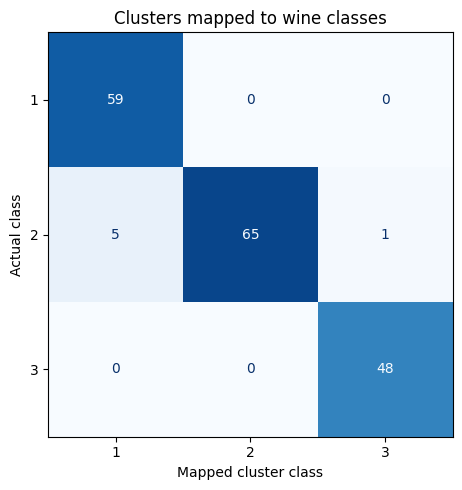

<Axes: title={'center': 'Clusters mapped to wine classes'}, xlabel='Mapped cluster class', ylabel='Actual class'>

In [28]:
def plot_cluster_confusion_matrix(
    true_labels: npt.ArrayLike,
    cluster_labels: npt.ArrayLike,
    *,
    ax: Axes | None = None,
    title: str = "Clusters mapped to wine classes",
) -> Axes:
    """Align cluster IDs with true classes and plot a confusion matrix."""
    actual = np.asarray(true_labels).ravel()
    clusters = np.asarray(cluster_labels).ravel()

    if len(actual) != len(clusters):
        raise ValueError("Both label arrays must have the same length.")

    # Match arbitrary cluster IDs to classes independently for each model.
    table = pd.crosstab(actual, clusters)

    if table.shape[0] != table.shape[1]:
        raise ValueError("The number of clusters must equal the number of classes.")

    rows, cols = linear_sum_assignment(-table.to_numpy())
    cluster_to_class = {
        table.columns[col]: table.index[row]
        for row, col in zip(rows, cols)
    }

    print("Cluster-to-class mapping:", cluster_to_class)

    predicted_classes = np.array([cluster_to_class[c] for c in clusters])

    standalone = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        actual,
        predicted_classes,
        labels=table.index.tolist(),
        cmap="Blues",
        colorbar=False,
        values_format="d",
        ax=ax,
        # Use the same colour range when comparing the same dataset.
        im_kw={"vmin": 0, "vmax": table.sum(axis=1).max()},
    )
    ax.set_title(title)
    ax.set_xlabel("Mapped cluster class")
    ax.set_ylabel("Actual class")

    if standalone:
        plt.tight_layout()
        plt.show()

    return ax

plot_cluster_confusion_matrix(true_labels, wines_predicted)

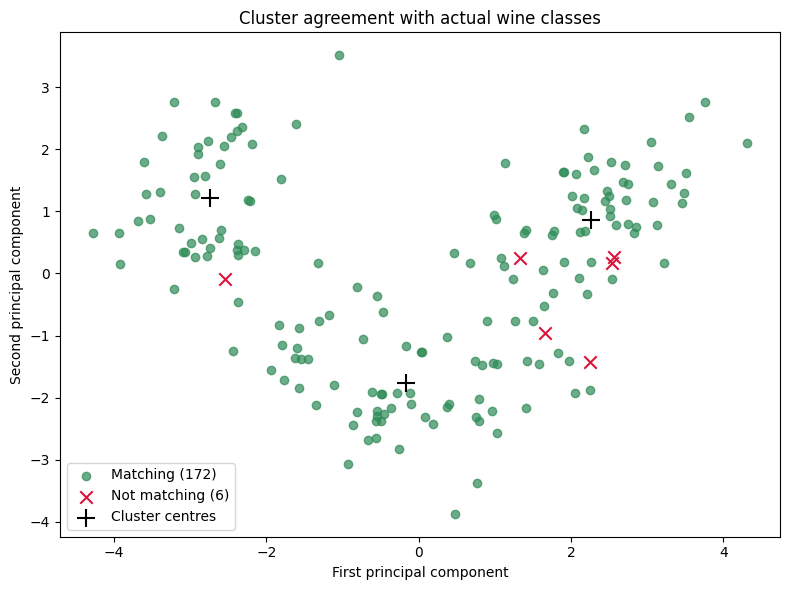

<Axes: title={'center': 'Cluster agreement with actual wine classes'}, xlabel='First principal component', ylabel='Second principal component'>

In [29]:
from matplotlib.axes import Axes

def plot_pca_cluster_agreement(
    pca_coordinates: npt.ArrayLike,
    true_labels: npt.ArrayLike,
    cluster_labels: npt.ArrayLike,
    *,
    pca_centroids: npt.ArrayLike | None = None,
    ax: Axes | None = None,
    title: str = "Cluster agreement with actual wine classes",
) -> Axes:
    """Plot class agreement after aligning cluster IDs with true classes.

    Samples must follow the same order in all inputs.
    Centroids must use the same PCA coordinate system as the samples.
    """
    coordinates = np.asarray(pca_coordinates)
    actual = np.asarray(true_labels).ravel()
    clusters = np.asarray(cluster_labels).ravel()

    if coordinates.ndim != 2 or coordinates.shape[1] < 2:
        raise ValueError("pca_coordinates must contain at least two components.")

    if not (len(coordinates) == len(actual) == len(clusters)):
        raise ValueError("Coordinates and labels must have the same sample count.")

    # Align arbitrary cluster IDs with classes for this experiment.
    table = pd.crosstab(actual, clusters)

    if table.shape[0] != table.shape[1]:
        raise ValueError("The number of clusters must equal the number of classes.")

    rows, cols = linear_sum_assignment(-table.to_numpy())
    cluster_to_class = {
        table.columns[col]: table.index[row]
        for row, col in zip(rows, cols)
    }
    mapped_labels = np.array([cluster_to_class[c] for c in clusters])
    matches = mapped_labels == actual

    centres = None
    if pca_centroids is not None:
        centres = np.asarray(pca_centroids)
        if centres.ndim != 2 or centres.shape[1] < 2:
            raise ValueError("pca_centroids must contain at least two components.")

    # Create a figure only when no subplot was supplied.
    standalone = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 6))

    ax.scatter(
        coordinates[matches, 0],
        coordinates[matches, 1],
        color="seagreen",
        alpha=0.7,
        label=f"Matching ({matches.sum()})",
    )
    ax.scatter(
        coordinates[~matches, 0],
        coordinates[~matches, 1],
        color="crimson",
        marker="x",
        s=80,
        label=f"Not matching ({(~matches).sum()})",
    )

    if centres is not None:
        ax.scatter(
            centres[:, 0],
            centres[:, 1],
            color="black",
            marker="+",
            s=180,
            label="Cluster centres",
        )

    ax.set_xlabel("First principal component")
    ax.set_ylabel("Second principal component")
    ax.set_title(title)
    ax.legend()

    if standalone:
        plt.tight_layout()
        plt.show()

    return ax

plot_pca_cluster_agreement(
    pca_coordinates=wines_p,
    true_labels=true_labels,
    cluster_labels=wines_predicted,
    pca_centroids=centroids,
)

<h1>Additional experiments</h1>

**Change one setting at a time** so you can explain what caused any difference.

Use your current model as the baseline:

| Experiment | Scaling | PCA | Clusters |
|---|---|---|---|
| Baseline | StandardScaler | 2 components | 3 |
| 1: Effect of scaling | None | 2 components | 3 |
| 2: Effect of retained variance | StandardScaler | Enough components for 90% variance | 3 |

Keep the same `random_state` and `n_init` across all runs.

Compare:

- **Adjusted Rand Index:** agreement with the known wine classes; higher is better.
- **PCA components and retained variance:** how much information each representation preserves.
- **Confusion matrix:** which classes are mixed together, recalculating the cluster-to-class mapping for each experiment.

**Don’t compare inertia directly across these experiments**, because scaling and changing dimensions alter the distances used to calculate it.

The unscaled experiment tests the effect of removing scaling. The 90% experiment tests whether retaining more information improves clustering—it may help, but improvement is not guaranteed.

**Pass the same integer `random_state` when creating each experiment’s K-means model**. Each fit then starts from a reproducible random seed; you don’t need to reset anything manually.

```python
# Use this configuration for each experiment
k_means = KMeans(
    init="k-means++",
    n_clusters=3,  # Keep at 3
    n_init=12,
    random_state=0
)
experiment_labels = k_means.fit_predict(experiment_data)
```

This makes each experiment repeatable, although different input data can still produce different initial centres and final clusters.

For a stronger comparison, repeat **all experiments with the same set of seeds**—for example, `0, 1, 2, 3, 4`—and compare their average ARI and variability.

<h2>Experiment 1: Effect of scaling</h2>

Cluster colours and raw cluster IDs are local to each fit; equal IDs need not represent corresponding groups. The agreement plots align IDs with classes separately for each model. The class mapping uses these same wines, so it is descriptive evaluation, not held-out accuracy.

In [30]:
# The experiment below fits K-means after unscaled PCA.
# Compare those assignments with the scaled PCA baseline once both are fitted.
# Do not substitute the preliminary 13-feature labels for PCA cluster labels.

In [31]:
pca_wines_unscaled = PCA(number_of_principal_components_to_keep)
pca_wines_unscaled.fit(X) # Instead of X_scaled

PCA(n_components=2)

In [32]:
def display_pca_variance_comparison(
    first_ratios: npt.ArrayLike,
    second_ratios: npt.ArrayLike,
    *,
    first_name: str = "Original PCA",
    second_name: str = "90% variance PCA",
) -> None:
    """Compare retained variance, allowing different component counts."""
    if first_name == second_name:
        raise ValueError("The experiment names must be different.")

    first = np.asarray(first_ratios).ravel()
    second = np.asarray(second_ratios).ravel()

    # Align components by position; absent components remain missing.
    comparison = pd.DataFrame({
        first_name: pd.Series(first),
        second_name: pd.Series(second),
    })
    comparison.index = [
        f"Component {i + 1}" for i in range(len(comparison))
    ]
    comparison.index.name = "Component"

    comparison.loc["Total retained"] = [first.sum(), second.sum()]

    display_table(
        comparison.reset_index(),
        formats={
            first_name: "{:.2%}",
            second_name: "{:.2%}",
        },
        latex_formats={
            first_name: lambda value: f"{value * 100:.2f}" + r"\%",
            second_name: lambda value: f"{value * 100:.2f}" + r"\%",
        },
        na_rep="—",
    )


display_pca_variance_comparison(
    pca_wines.explained_variance_ratio_,
    pca_wines_unscaled.explained_variance_ratio_,
    first_name="Scaled",
    second_name="Unscaled",
)
display(Markdown(
    "These ratios describe different feature spaces. A higher retained "
    "percentage in unscaled PCA may reflect domination by large-range features, "
    "rather than better class separation."
))

Component,Scaled,Unscaled
Component 1,36.20%,99.81%
Component 2,19.21%,0.17%
Total retained,55.41%,99.98%


These ratios describe different feature spaces. A higher retained percentage in unscaled PCA may reflect domination by large-range features, rather than better class separation.

In [33]:
# Transform unscaled measurements using the PCA fitted on unscaled X.
wines_p_unscaled = pca_wines_unscaled.transform(X)

In [34]:
# Use the same K-means settings as the scaled two-component baseline.
km_unscaled = KMeans(init="k-means++", n_clusters=clusterNum, n_init=12, random_state=0)
km_unscaled

KMeans(n_clusters=3, n_init=12, random_state=0)

In [35]:
# cluster the wines using only their 2 principal components,
# and keep the coordinates of the 3 cluster centres
wines_predicted_unscaled = km_unscaled.fit_predict(wines_p_unscaled)
centroids_unscaled = km_unscaled.cluster_centers_
centroids_unscaled

# Compare the two PCA clusterings after aligning arbitrary IDs.
assignment_table = pd.crosstab(wines_predicted, wines_predicted_unscaled)
assignment_rows, assignment_cols = linear_sum_assignment(-assignment_table.to_numpy())
unscaled_to_baseline = {
    assignment_table.columns[col]: assignment_table.index[row]
    for row, col in zip(assignment_rows, assignment_cols)
}
aligned_unscaled = np.array([unscaled_to_baseline[c] for c in wines_predicted_unscaled])
changed = wines_predicted != aligned_unscaled
assignment_comparison = pd.DataFrame({
    "Baseline PCA cluster": wines_predicted,
    "Unscaled PCA cluster (aligned)": aligned_unscaled,
}, index=data.index)
print(f"{changed.sum()} of {len(changed)} wines changed groups after ID alignment.")
display_table(
    assignment_comparison.loc[changed].rename_axis("Wine row").reset_index()
)

55 of 178 wines changed groups after ID alignment.


Wine row,Baseline PCA cluster,Unscaled PCA cluster (aligned)
4,1,2
19,1,2
20,1,2
21,1,2
24,1,2
25,1,2
28,1,2
35,1,2
36,1,2
39,1,2


In [36]:
#pd.Series(wines_predicted_unscaled).value_counts()

cluster_counts = pd.concat(
    [
        pd.Series(wines_predicted).value_counts().rename("Scaled"),
        pd.Series(wines_predicted_unscaled).value_counts().rename("Unscaled"),
    ],
    axis=1,
).fillna(0).astype(int).sort_index()

display_table(
    cluster_counts.rename_axis("Cluster").reset_index()
)

Cluster,Scaled,Unscaled
0,65,69
1,64,47
2,49,62


In [37]:
display(Markdown("Raw cluster IDs are arbitrary: a row with the same ID need not describe the same group in both models."))

Raw cluster IDs are arbitrary: a row with the same ID need not describe the same group in both models.

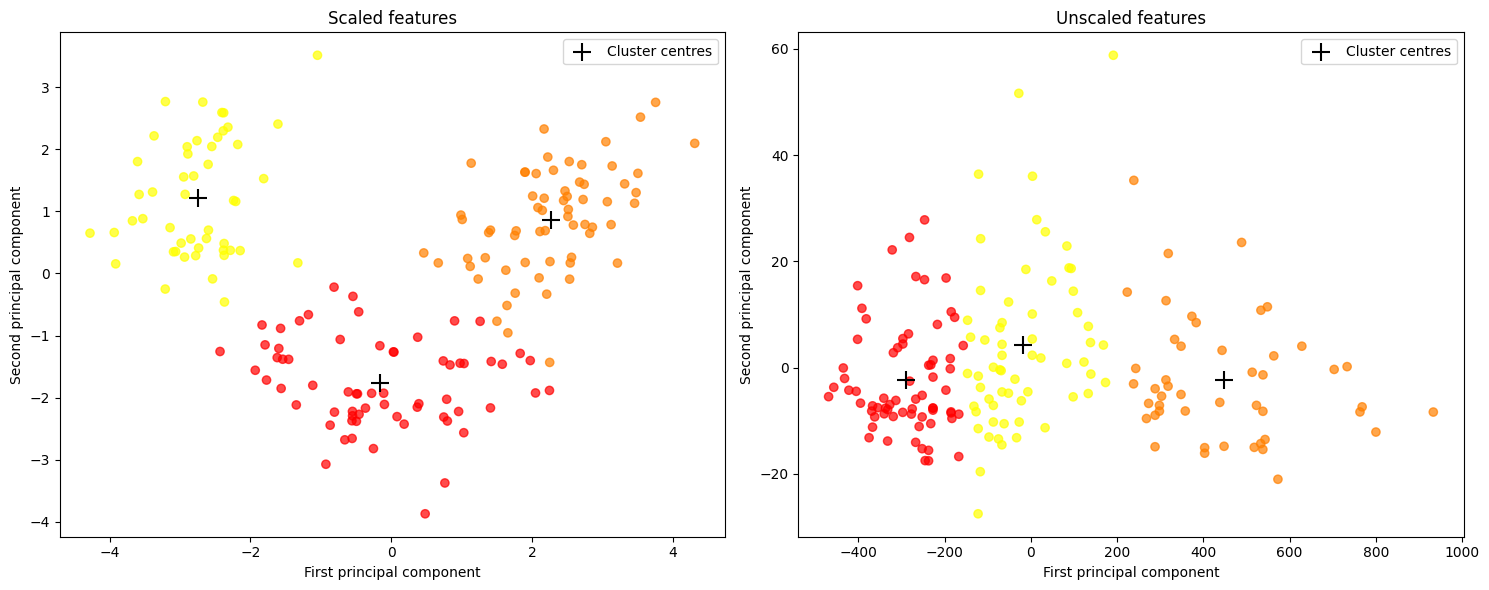

In [38]:
#plot_pca_clusters(wines_p_unscaled, wines_predicted_unscaled, centroids_unscaled)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

plot_pca_clusters(
    wines_p,
    wines_predicted,
    centroids,
    ax=axes[0],
    title="Scaled features",
)

plot_pca_clusters(
    wines_p_unscaled,
    wines_predicted_unscaled,
    centroids_unscaled,
    ax=axes[1],
    title="Unscaled features",
)

fig.tight_layout()
plt.show()

In [39]:
score_unscaled = adjusted_rand_score(true_labels, wines_predicted_unscaled)
#print(f"Adjusted Rand Index: {score_unscaled:.3f}")
display(Markdown(f"Adjusted Rand Index:\n\n- Unscaled: {score_unscaled:.3f}\n- Scaled: {score:.3f}"))

Adjusted Rand Index:

- Unscaled: 0.371
- Scaled: 0.895

Cluster-to-class mapping: {1: 1, 0: 2, 2: 3}
Cluster-to-class mapping: {1: 1, 0: 2, 2: 3}


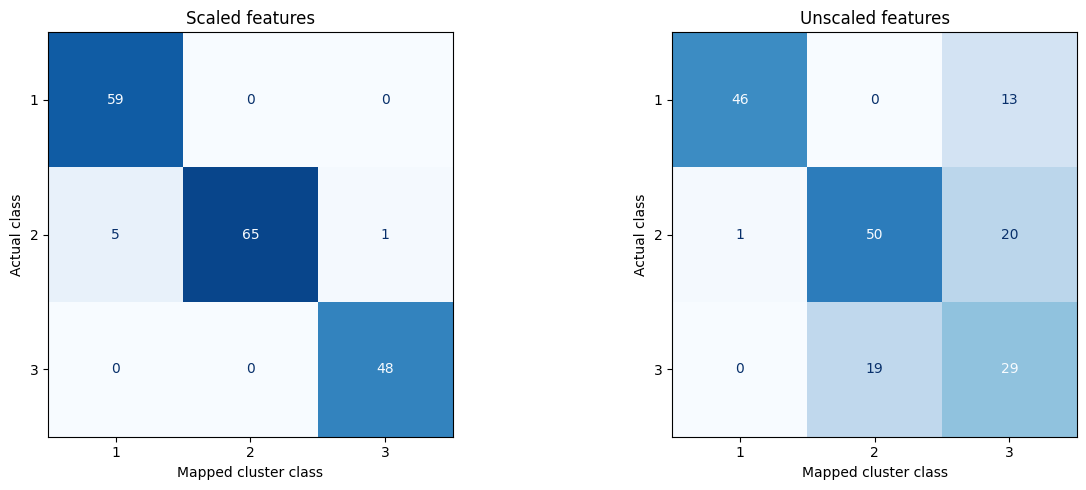

In [40]:
#plot_cluster_confusion_matrix(true_labels, wines_predicted_unscaled)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_cluster_confusion_matrix(
    true_labels,
    wines_predicted,
    ax=axes[0],
    title="Scaled features",
)

plot_cluster_confusion_matrix(
    true_labels,
    wines_predicted_unscaled,
    ax=axes[1],
    title="Unscaled features",
)

fig.tight_layout()
plt.show()

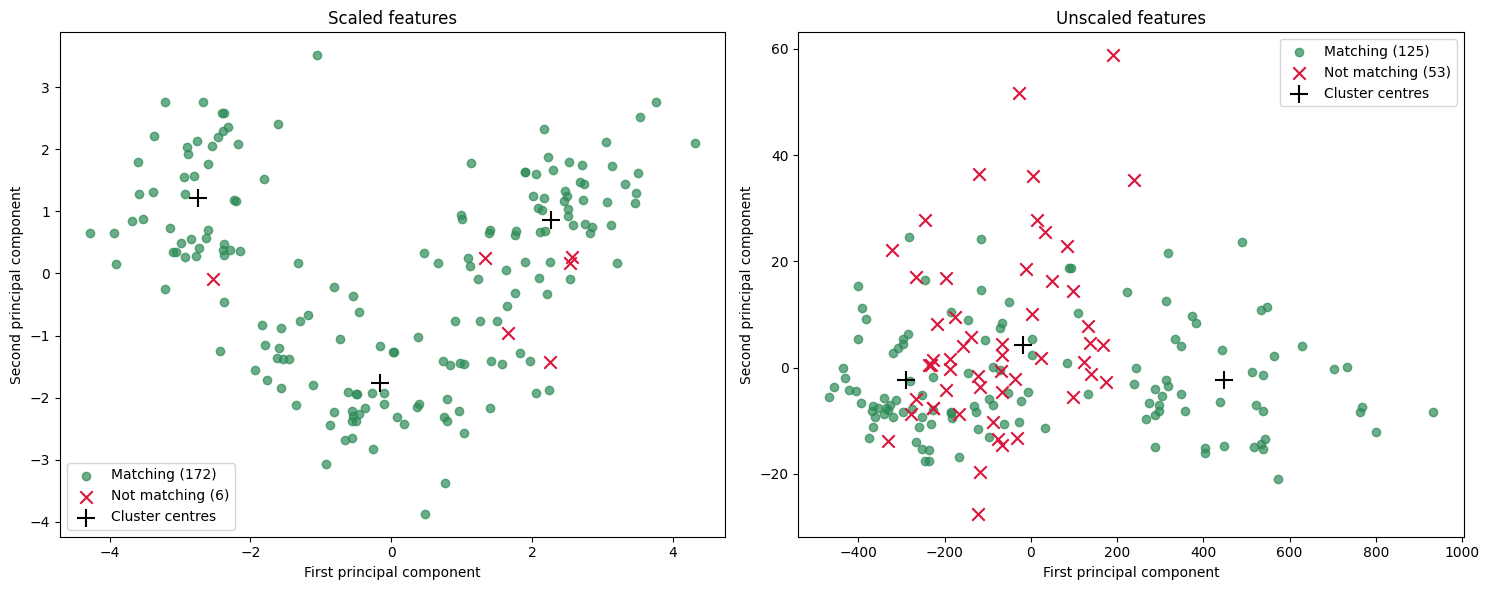

In [41]:
'''plot_pca_cluster_agreement(
    pca_coordinates=wines_p_unscaled,
    true_labels=true_labels,
    cluster_labels=wines_predicted_unscaled,
    pca_centroids=centroids_unscaled,
)'''

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

plot_pca_cluster_agreement(
    wines_p,
    true_labels,
    wines_predicted,
    pca_centroids=centroids,
    ax=axes[0],
    title="Scaled features",
)

plot_pca_cluster_agreement(
    wines_p_unscaled,
    true_labels,
    wines_predicted_unscaled,
    pca_centroids=centroids_unscaled,
    ax=axes[1],
    title="Unscaled features",
)

fig.tight_layout()
plt.show()

In [42]:
print(f"Scaled ARI:   {adjusted_rand_score(true_labels, wines_predicted):.3f}")
print(f"Unscaled ARI: {adjusted_rand_score(true_labels, wines_predicted_unscaled):.3f}")

Scaled ARI:   0.895
Unscaled ARI: 0.371


<h2>Experiment 2: Retaining more variance</h2>

Keep standardisation and the K-means settings unchanged. Fit a separate PCA to
retain at least 90% of the scaled variance, then cluster using **all retained
components**. The side-by-side scatter plots show only the first two components,
so they do not show all distances used by this model.

The variable suffix `_improved` identifies this experiment; it does not assume
that retaining more variance must improve agreement.

In [43]:
pca_variance_retained = 0.90

pca_wines_improved = PCA(n_components=pca_variance_retained)
pca_wines_improved.fit(X_scaled)

PCA(n_components=0.9)

In [44]:
display_pca_explained_variance(pca_wines_improved.explained_variance_ratio_)

number_of_principal_components_improved = len(pca_wines_improved.explained_variance_ratio_)

Component,Explained variance ratio
Component 1,0.3620
Component 2,0.1921
Component 3,0.1112
Component 4,0.0707
Component 5,0.0656
Component 6,0.0494
Component 7,0.0424
Component 8,0.0268
Total,0.9202


We're keeping 8 principal components. They retain 92.02% of the total variance.

In [45]:
wines_p_improved = pca_wines_improved.transform(X_scaled)

km_improved = KMeans(init="k-means++", n_clusters=clusterNum, n_init=12, random_state=0)
km_improved

KMeans(n_clusters=3, n_init=12, random_state=0)

In [46]:
wines_predicted_improved = km_improved.fit_predict(wines_p_improved)
centroids_improved = km_improved.cluster_centers_
centroids_improved

array([[-3.69566084e-02, -1.77223945e+00,  1.86138728e-01,
         8.02397126e-02,  7.08780744e-02, -1.29805766e-01,
        -2.32728507e-03,  1.80153234e-02],
       [-2.72003575e+00,  1.12565126e+00, -2.39093241e-01,
         6.24569372e-02,  7.36759999e-02, -9.99252193e-02,
        -6.03831729e-02,  7.38798948e-03],
       [ 2.27619360e+00,  9.32054027e-01,  1.52803156e-03,
        -1.35498147e-01, -1.34912110e-01,  2.18283242e-01,
         5.21099249e-02, -2.49642497e-02]])

In [47]:
display_pca_variance_comparison(
    pca_wines.explained_variance_ratio_,
    pca_wines_improved.explained_variance_ratio_,
    first_name=f"Original PCA ({number_of_principal_components_to_keep} components)",
    second_name=f"PCA retaining {pca_variance_retained:.0%}",
)

Component,Original PCA (2 components),PCA retaining 90%
Component 1,36.20%,36.20%
Component 2,19.21%,19.21%
Component 3,—,11.12%
Component 4,—,7.07%
Component 5,—,6.56%
Component 6,—,4.94%
Component 7,—,4.24%
Component 8,—,2.68%
Total retained,55.41%,92.02%


In [48]:
cluster_counts = pd.concat(
    [
        pd.Series(wines_predicted).value_counts().rename(f"Using {number_of_principal_components_to_keep} Principal Components"),
        pd.Series(wines_predicted_improved).value_counts().rename(f"Using {number_of_principal_components_improved} Principal Components"),
    ],
    axis=1,
).fillna(0).astype(int).sort_index()

display_table(
    cluster_counts.rename_axis("Cluster").reset_index()
)

display(Markdown("Raw cluster IDs are arbitrary: a row with the same ID need not describe the same group in both models."))

Cluster,Using 2 Principal Components,Using 8 Principal Components
0,65,65
1,64,51
2,49,62


Raw cluster IDs are arbitrary: a row with the same ID need not describe the same group in both models.

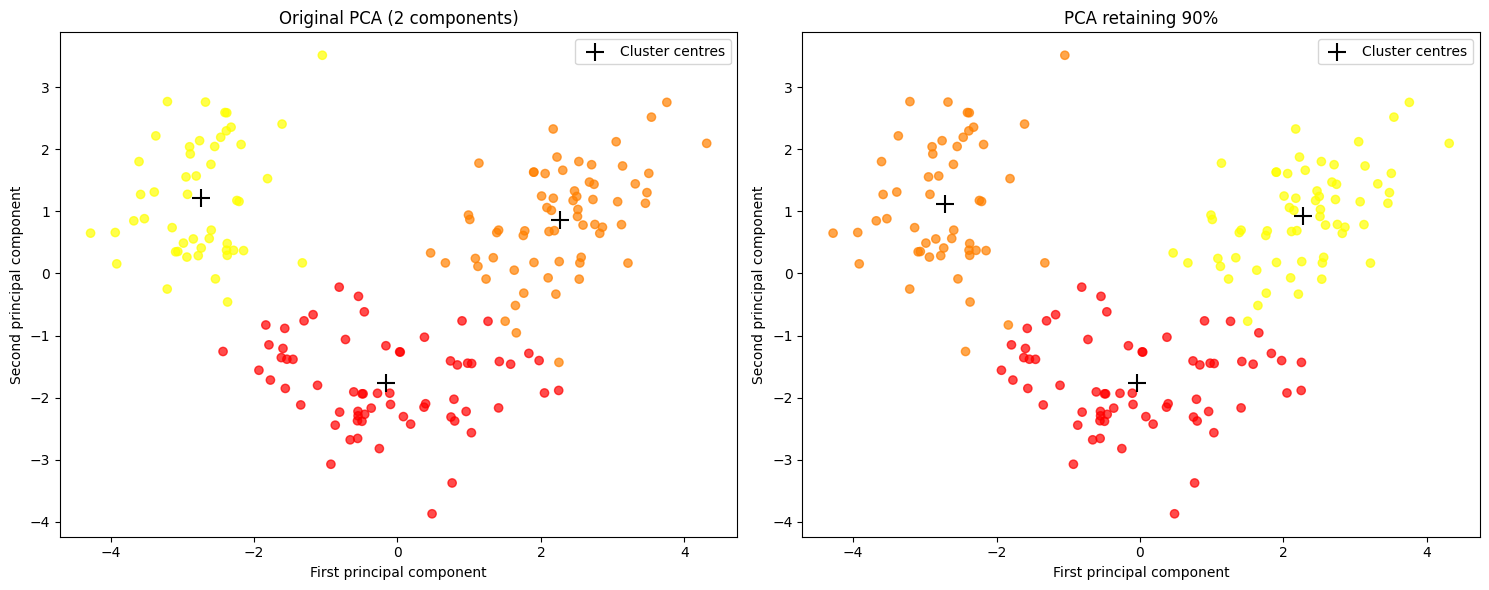

In [49]:
original_title_str = f"Original PCA ({number_of_principal_components_to_keep} components)"
improved_title_str = f"PCA retaining {pca_variance_retained:.0%}"

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

plot_pca_clusters(
    wines_p,
    wines_predicted,
    centroids,
    ax=axes[0],
    title=original_title_str,
)

plot_pca_clusters(
    wines_p_improved,
    wines_predicted_improved,
    centroids_improved,
    ax=axes[1],
    title=improved_title_str,
)

fig.tight_layout()
plt.show()

Cluster-to-class mapping: {1: 1, 0: 2, 2: 3}
Cluster-to-class mapping: {2: 1, 0: 2, 1: 3}


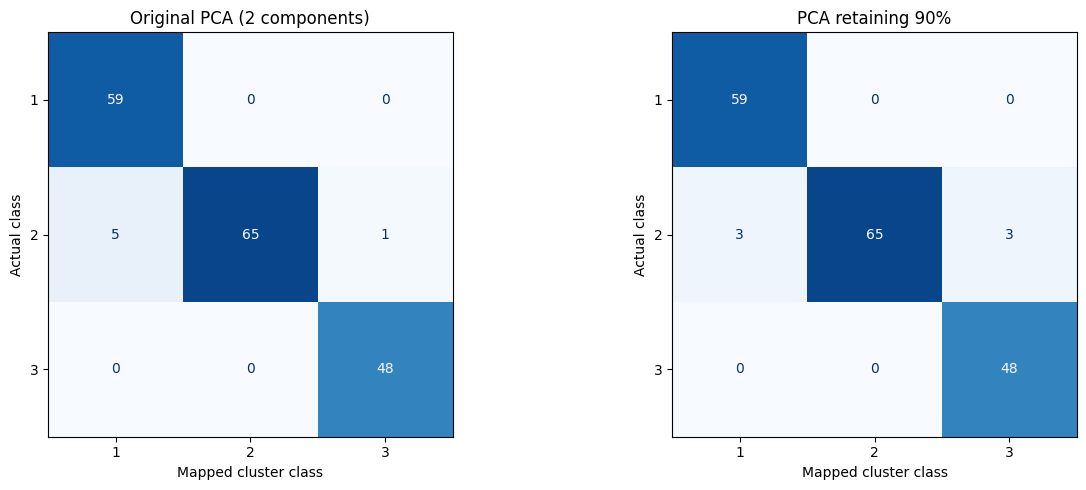

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

plot_cluster_confusion_matrix(
    true_labels,
    wines_predicted,
    ax=axes[0],
    title=original_title_str,
)

plot_cluster_confusion_matrix(
    true_labels,
    wines_predicted_improved,
    ax=axes[1],
    title=improved_title_str,
)

fig.tight_layout()
plt.show()

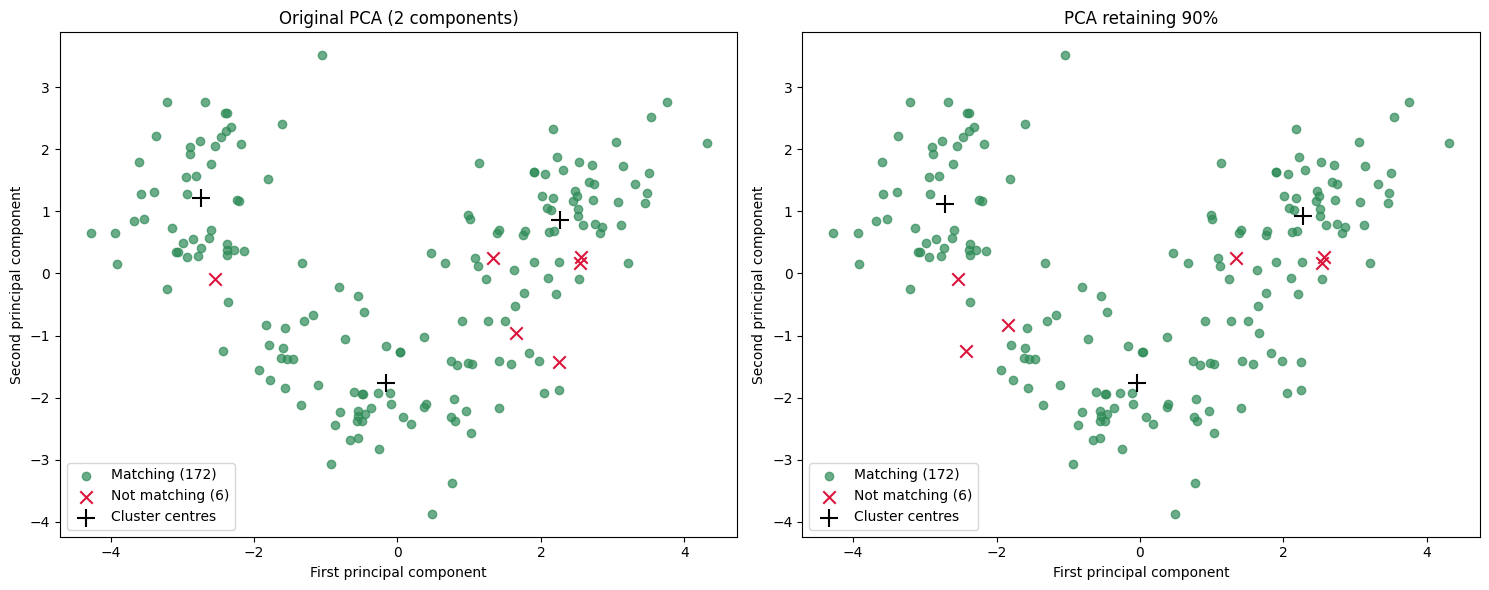

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

plot_pca_cluster_agreement(
    wines_p,
    true_labels,
    wines_predicted,
    pca_centroids=centroids,
    ax=axes[0],
    title=original_title_str,
)

plot_pca_cluster_agreement(
    wines_p_improved,
    true_labels,
    wines_predicted_improved,
    pca_centroids=centroids_improved,
    ax=axes[1],
    title=improved_title_str,
)

fig.tight_layout()
plt.show()

In [52]:
# Compare all three PCA experiments on the same wines.
experiment_summary = pd.DataFrame({
    "Experiment": [f"Scaled: {number_of_principal_components_to_keep} PCs", f"Unscaled: {number_of_principal_components_to_keep} PCs", f"Scaled: {pca_variance_retained:.0%} variance"],
    "Components": [
        pca_wines.n_components_, pca_wines_unscaled.n_components_,
        pca_wines_improved.n_components_,
    ],
    "Retained variance": [
        pca_wines.explained_variance_ratio_.sum(),
        pca_wines_unscaled.explained_variance_ratio_.sum(),
        pca_wines_improved.explained_variance_ratio_.sum(),
    ],
    "ARI": [
        adjusted_rand_score(true_labels, wines_predicted),
        adjusted_rand_score(true_labels, wines_predicted_unscaled),
        adjusted_rand_score(true_labels, wines_predicted_improved),
    ],
})
display_table(
    experiment_summary,
    formats={"Retained variance": "{:.2%}", "ARI": "{:.3f}"},
    latex_formats={"Retained variance": lambda value: f"{value * 100:.2f}" + r"\%"},
)
display(Markdown(
    "Retained variance for unscaled PCA has a different denominator from "
    "scaled PCA. Compare class agreement using ARI, not retained variance alone."
))

Experiment,Components,Retained variance,ARI
Scaled: 2 PCs,2,55.41%,0.895
Unscaled: 2 PCs,2,99.98%,0.371
Scaled: 90% variance,8,92.02%,0.897


Retained variance for unscaled PCA has a different denominator from scaled PCA. Compare class agreement using ARI, not retained variance alone.

<h1>What did we learn?</h1>

- **Scaling matters for this dataset.** Large-range measurements dominate unscaled
  distances. Compare the ARI values below the experiments to quantify the effect.
- **The elbow is a heuristic.** The 13-feature scaled curve suggests three clusters;
  this count is held fixed across the PCA experiments.
- **PCA and clustering are separate steps.** The preliminary model uses 13 features,
  the baseline uses two PCs, and experiment 2 uses enough PCs to retain at least
  90% of scaled variance.
- **Two PCs provide a partial view.** The baseline retains about 55.4% of scaled
  variance. More retained variance does not guarantee better class agreement.
- **Evaluation uses the supplied classes.** ARI is invariant to cluster numbering.
  Confusion matrices and agreement plots align cluster IDs with classes using
  these same wines; they do not measure held-out classification accuracy.
- **Visualisation is partly supervised.** ANOVA uses class labels to select three
  plotting features, but those labels are excluded from PCA and K-means fitting.